# Seminari 3 · A* search

**CIS525 · Inteligjenca Artificiale · UET**

Kodi, figurat, kontrollet dhe ndërfaqja ndodhen në këtë notebook. Të dhënat lexohen nga `../data/shared/` dhe `../data/seminar3/`. Përdor **Restart Kernel and Run All Cells** nga rrënja e projektit ose dosja `notebooks/`. Për ta kopjuar mësimin, ruaj edhe dosjet përkatëse të të dhënave.

**Gjendja / Status:** demonstrim i starter-it dhe përshtatjes së grafeve; heuristika mbetet `h = 0`. Detyra e plotë e seminarit mbetet në punë.

In [9]:
%matplotlib inline
import csv
import heapq
import json
from collections import deque
from itertools import pairwise
from math import isqrt
from pathlib import Path
from tempfile import TemporaryDirectory

import ipywidgets as widgets
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
def find_data_dir(start=None):
    """Find data/ from the repository root or the notebooks directory."""
    start = Path.cwd() if start is None else Path(start)
    start = start.resolve()
    for directory in (start, *start.parents):
        if (directory / "data").is_dir():
            return directory / "data"
    raise FileNotFoundError("Cannot find data/. Keep it alongside notebooks/ and launch from the project.")

DATA_DIR = find_data_dir()

def parse_maze_config(text):
    """Validate JSON maze settings before constructing the graph."""
    config = json.loads(text)
    required = {"rooms", "entrance", "exit"}
    if not isinstance(config, dict) or not required <= config.keys():
        raise ValueError("maze_config.json: expected rooms, entrance and exit")
    if any(type(config[key]) is not int for key in required):
        raise ValueError("maze_config.json: settings must be integers")
    rooms = config["rooms"]
    if rooms <= 0 or isqrt(rooms) ** 2 != rooms:
        raise ValueError("maze_config.json: rooms must be a positive perfect square")
    if not 1 <= config["entrance"] <= rooms or not 1 <= config["exit"] <= rooms:
        raise ValueError("maze_config.json: entrance and exit must be existing rooms")
    if config["entrance"] == config["exit"]:
        raise ValueError("maze_config.json: entrance and exit must be different")
    return config


## 1. Modeli dhe të dhënat / State space

Grafi ka formën `{nyje: [(fqinj, kosto), ...]}`. Rrugët ruhen në të dy drejtimet. Nisja është **TR**, qëllimi **GJ**.

Peshat merren nga kodi fillestar i projektit. Kostoja **FR–TP = 83** është supozimi i dokumentuar në kod, sepse në slajd nuk jepet peshë për atë lidhje. Rezultati 278 varet nga ky supozim.

In [10]:
def load_undirected_csv(path, cost_column="km", node_type=str):
    """Read each undirected edge once, validate it, then add both directions."""
    graph, seen = {}, set()
    with path.open(encoding="utf-8-sig", newline="") as stream:
        reader = csv.DictReader(stream)
        required = {"city_a", "city_b", cost_column} if cost_column else {"room_a", "room_b"}
        if not required <= set(reader.fieldnames or []):
            raise ValueError(f"{path}: missing columns {sorted(required)}")
        node_columns = ("city_a", "city_b") if cost_column else ("room_a", "room_b")
        for row in reader:
            try:
                if None in row or any(not row[key] or not row[key].strip() for key in required):
                    raise ValueError("missing or extra values")
                a, b = (node_type(row[key].strip()) for key in node_columns)
                cost = int(row[cost_column]) if cost_column else 1
                if a == b or cost <= 0 or frozenset((a, b)) in seen:
                    raise ValueError("self-edge, non-positive cost or duplicate edge")
            except (ValueError, TypeError) as error:
                raise ValueError(f"{path} line {reader.line_num}: {error}") from error
            seen.add(frozenset((a, b)))
            graph.setdefault(a, []).append((b, cost))
            graph.setdefault(b, []).append((a, cost))
    if not graph:
        raise ValueError(f"{path}: no edges found")
    return graph

graph_data = load_undirected_csv(DATA_DIR / "seminar3/starter_roads.csv")

START = 'TR'  # black node in the slide
GOAL = 'GJ'  # red node in the slide

def path_cost(graph, path):
    """Sum the weights of consecutive edges on a valid path."""
    return sum(dict(graph[a])[b] for a, b in pairwise(path))


starter_roads = [
    {"from": a, "to": b, "cost": cost}
    for a, edges in graph_data.items() for b, cost in edges if a < b
]
display(pd.DataFrame(starter_roads))
print("Cities:", len(graph_data), "Roads:", len(starter_roads))
assert (len(graph_data), len(starter_roads)) == (12, 15)
assert all((a, cost) in graph_data[b] for a, edges in graph_data.items() for b, cost in edges)

,from,to,cost
0,LE,TR,55
1,LE,SH,35
2,DR,TR,40
3,DR,LU,40
4,EL,TR,35
5,EL,LU,45
6,FR,LU,80
7,FR,VL,35
8,FR,TP,83
9,TP,VL,60


Cities: 12 Roads: 15


## 2. Algoritmi / Algorithm

A* zgjedh nyjen me `f(n) = g(n) + h(n)`: `g` është kostoja e rrugës së gjetur deri te nyja dhe `h` vlerëson koston e mbetur. Kodi ruan paraardhësin te `Node.parent` për të rindërtuar rrugën.

Në këtë starter **h = 0 për çdo nyje**, prandaj renditja bëhet vetëm nga `g`: kërkimi sillet si Dijkstra. Nuk kemi një demonstrim të përshpejtimit nga heuristika. Për një A* të informuar kërkohet një heuristikë e përshtatshme; ky implementim mbyll nyjet pa i rihapur dhe nuk duhet përgjithësuar pa analizë për heuristika jokonsistente.

Qeliza përmban klasën dhe funksionin që ekzekutohen realisht. Implementimi është në notebook dhe mund të ndryshohet drejtpërdrejt.

In [11]:
class Node:
    def __init__(self, position, parent=None):
        self.position = position
        self.parent = parent
        self.g = 0  # Cost from start node to current node
        self.h = 0  # Heuristic cost from current node to end node
        self.f = 0  # Total cost (g + h)

    def __lt__(self, other):
        return self.f < other.f


def a_star_search(graph, start, end):
    """
    Implements the A* search algorithm.

    Args:
        graph (dict): A dictionary representing the graph where keys are nodes
                      and values are lists of connected nodes and their costs.
                      Example: {'A': [('B', 1), ('C', 3)], 'B': [('D', 2)], ...}
        start (str): The starting node.
        end (str): The destination node.

    Returns:
        list: The path from start to end if found, otherwise None.
    """
    start_node = Node(start) # starts the node
    end_node = Node(end) # starts the end node

    open_list = [] # stores the nodes to be evaluated
    closed_list = set() # stores the nodes that have been evaluated

    heapq.heappush(open_list, start_node) # pushes the start node onto the open list

    while open_list: # while loop for the open list
        current_node = heapq.heappop(open_list) # pops the node with the lowest f value from the open list
        closed_list.add(current_node.position) # adds the current node to the closed list

        if current_node.position == end_node.position: # checks if the current node is the end node
            path = [] # stores the path from start to end
            while current_node is not None: # checks if the current node is not None
                path.append(current_node.position) # adds the current node to the path
                current_node = current_node.parent # moves to the parent node
            return path[::-1]  # Return reversed path

        if current_node.position in graph:
            for neighbor_pos, cost in graph[current_node.position]:
                if neighbor_pos in closed_list:
                    continue

                neighbor = Node(neighbor_pos, current_node)
                neighbor.g = current_node.g + cost
                # For a basic example, we can use Manhattan distance or a simple
                # straight-line distance as a heuristic if coordinates are available.
                # Here, we'll use a placeholder heuristic (e.g., 0 for simplicity,
                # or a pre-calculated value if a more informed heuristic is desired).
                neighbor.h = 0  # Placeholder heuristic
                neighbor.f = neighbor.g + neighbor.h

                # Check if neighbor is already in open_list with a higher f value
                in_open_list = False
                for node_in_open in open_list:
                    if neighbor.position == node_in_open.position and neighbor.f >= node_in_open.f:
                        in_open_list = True
                        break

                if not in_open_list:
                    heapq.heappush(open_list, neighbor)

    return None  # Path not found

## 3. Zgjidhja TR → GJ / Starter result

Rruga e referencës është **TR → EL → LU → FR → TP → GJ**, me kosto **278**. Tabela e llogarit shumën nga lidhjet e grafit, jo nga një numër i shkruar në figurë.

In [12]:
starter_path = a_star_search(graph_data, START, GOAL)
starter_cost = path_cost(graph_data, starter_path)
legs = pd.DataFrame([
    {"from": a, "to": b, "cost": dict(graph_data[a])[b]}
    for a, b in zip(starter_path, starter_path[1:], strict=False)
])
legs["cumulative_cost"] = legs["cost"].cumsum()
display(legs)
print("Path:", " → ".join(starter_path))
print("Total cost:", starter_cost)

,from,to,cost,cumulative_cost
0,TR,EL,35,35
1,EL,LU,45,80
2,LU,FR,80,160
3,FR,TP,83,243
4,TP,GJ,35,278


Path: TR → EL → LU → FR → TP → GJ
Total cost: 278


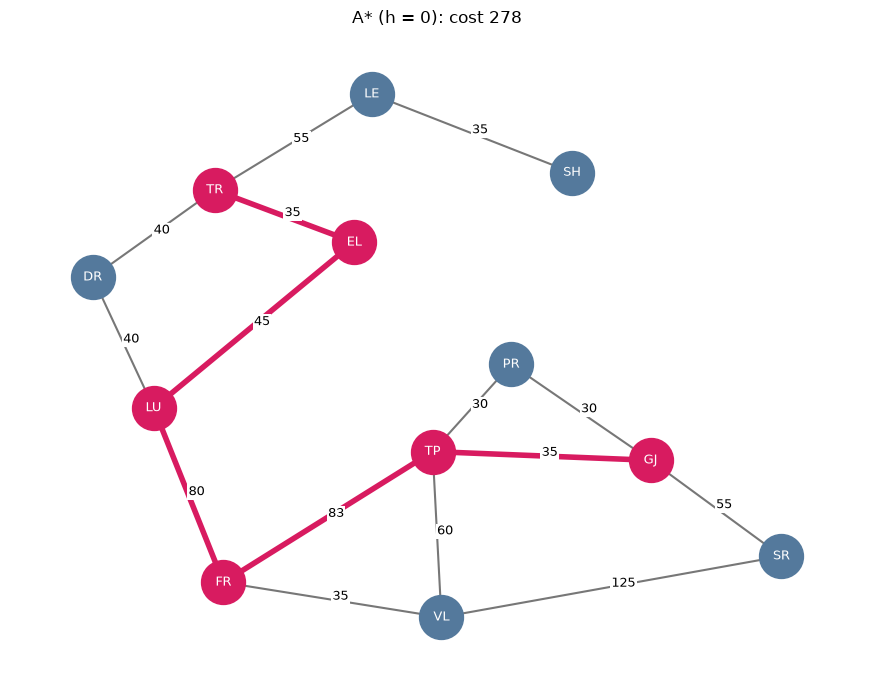

In [13]:
STARTER_POS = {
    "LE": (5.6, -2.4), "SH": (7.9, -3.3), "TR": (3.8, -3.5), "EL": (5.4, -4.1),
    "DR": (2.4, -4.5), "LU": (3.1, -6.0), "PR": (7.2, -5.5), "TP": (6.3, -6.5),
    "GJ": (8.8, -6.6), "SR": (10.3, -7.7), "FR": (3.9, -8.0), "VL": (6.4, -8.4),
}


def plot_route(graph, positions, path, title):
    """Draw the current graph and route directly in the notebook."""
    highlighted = {frozenset((a, b)) for a, b in pairwise(path or [])}
    fig, ax = plt.subplots(figsize=(10, 7))
    drawn = set()
    for a, edges in graph.items():
        for b, cost in edges:
            edge = frozenset((a, b))
            if edge in drawn:
                continue
            drawn.add(edge)
            x1, y1 = positions[a]
            x2, y2 = positions[b]
            selected = edge in highlighted
            ax.plot([x1, x2], [y1, y2], color="#d81b60" if selected else "#777777",
                    linewidth=4 if selected else 1.5, zorder=1)
            ax.text((x1+x2)/2, (y1+y2)/2, str(cost), fontsize=9,
                    bbox={"facecolor": "white", "edgecolor": "none", "pad": 1}, zorder=3)
    for node, (x, y) in positions.items():
        ax.scatter(x, y, s=1000, color="#d81b60" if node in (path or []) else "#54799c", zorder=2)
        ax.text(x, y, str(node), ha="center", va="center", color="white", fontsize=9, zorder=4)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.margins(0.12)
    ax.axis("off")
    fig.tight_layout()
    display(fig)
    plt.close(fig)


plot_route(graph_data, STARTER_POS, starter_path, f"A* (h = 0): cost {starter_cost}")

## 4. Përshtatja e grafeve / Graph adaptation

Përshtatja ndryshon vetëm formën e të dhënave: distancat e qyteteve ruhen dhe çdo derë e labirintit merr kosto 1. Të dhënat lexohen nga të njëjtët skedarë në `../data/shared/` si në Seminarin 2; nuk kopjohen më brenda notebook-ut.

Për krahasim përdorim Dijkstra të pavarur dhe BFS. Krahasojmë **kostot**, sepse rendi i fqinjëve mund të zgjedhë një rrugë tjetër me të njëjtën kosto.

In [14]:
city_graph = load_undirected_csv(DATA_DIR / "shared/cities.csv")
city_adjacency = {city: dict(edges) for city, edges in city_graph.items()}
maze_config = parse_maze_config((DATA_DIR / "shared/maze_config.json").read_text(encoding="utf-8"))
door_graph = load_undirected_csv(DATA_DIR / "shared/maze_doors.csv", cost_column=None, node_type=int)
rooms = maze_config["rooms"]
if set(door_graph) != set(range(1, rooms + 1)):
    raise ValueError("maze_doors.csv: every configured room must appear")
maze_adjacency = {room: sorted(neighbour for neighbour, _ in edges) for room, edges in door_graph.items()}
MAZE_DOORS = [(a, b) for a, neighbours in maze_adjacency.items() for b in neighbours if a < b]
width = isqrt(rooms)
for a, neighbours in maze_adjacency.items():
    if not 2 <= len(neighbours) <= 4:
        raise ValueError(f"maze_doors.csv: room {a} must have 2 to 4 doors")
    for b in neighbours:
        if abs((a - 1) // width - (b - 1) // width) + abs((a - 1) % width - (b - 1) % width) != 1:
            raise ValueError(f"maze_doors.csv: rooms {a} and {b} are not grid neighbours")
entrance, exit_room = maze_config["entrance"], maze_config["exit"]


def to_astar(adjacency):
    """Keep weighted costs; assign one unit to every unweighted edge."""
    return {
        node: sorted(neighbours.items()) if isinstance(neighbours, dict)
        else [(neighbour, 1) for neighbour in sorted(neighbours)]
        for node, neighbours in adjacency.items()
    }


def reference_shortest_path(graph, start, goal):
    """Independent Dijkstra reference, returning (path, cost)."""
    if start not in graph or goal not in graph:
        return None, None
    distances, previous, frontier = {start: 0}, {start: None}, [(0, start)]
    while frontier:
        cost, node = heapq.heappop(frontier)
        if cost != distances[node]:
            continue
        if node == goal:
            path = []
            while node is not None:
                path.append(node)
                node = previous[node]
            return path[::-1], cost
        for neighbour, weight in graph[node]:
            candidate = cost + weight
            if candidate < distances.get(neighbour, float("inf")):
                distances[neighbour], previous[neighbour] = candidate, node
                heapq.heappush(frontier, (candidate, neighbour))
    return None, None


def bfs_path(adjacency, start, goal):
    """Independent FIFO reference for unit-cost doors."""
    if start not in adjacency or goal not in adjacency:
        return None
    previous, frontier = {start: None}, deque([start])
    while frontier:
        node = frontier.popleft()
        if node == goal:
            path = []
            while node is not None:
                path.append(node)
                node = previous[node]
            return path[::-1]
        for neighbour in sorted(adjacency[node]):
            if neighbour not in previous:
                previous[neighbour] = node
                frontier.append(neighbour)
    return None


astar_cities, astar_maze = to_astar(city_adjacency), to_astar(maze_adjacency)
cities_path = a_star_search(astar_cities, "Shkodër", "Korçë")
rooms_path = a_star_search(astar_maze, entrance, exit_room)
city_reference = reference_shortest_path(astar_cities, "Shkodër", "Korçë")
maze_reference_path = bfs_path(maze_adjacency, entrance, exit_room)
maze_reference = (maze_reference_path, len(maze_reference_path) - 1)
comparison = pd.DataFrame([
    {"problem": "Cities", "A* (h=0)": path_cost(astar_cities, cities_path),
     "reference": city_reference[1], "unit": "km"},
    {"problem": "Maze", "A* (h=0)": path_cost(astar_maze, rooms_path),
     "reference": maze_reference[1], "unit": "doors"},
])
display(comparison)
print("Cities:", " → ".join(cities_path))
print("Maze:", " → ".join(map(str, rooms_path)))

,problem,A* (h=0),reference,unit
0,Cities,267,267,km
1,Maze,12,12,doors


Cities: Shkodër → Lezhë → Tirana → Elbasan → Korçë
Maze: 1 → 2 → 3 → 8 → 13 → 18 → 17 → 16 → 21 → 22 → 23 → 24 → 25


## 5. Verifikimi dhe eksperimente / Checks and experiments

Kontrollet përfshijnë rezultatin e starter-it, ruajtjen e kostove gjatë konvertimit, nyje të izoluara dhe nisjen që është njëkohësisht qëllim. Me peshat pozitive të starter-it, krahasojmë gjithashtu çdo çift qytetesh me Dijkstra.

In [15]:
assert starter_path == ["TR", "EL", "LU", "FR", "TP", "GJ"]
assert starter_cost == 278
assert path_cost(astar_cities, cities_path) == city_reference[1] == 267
assert path_cost(astar_maze, rooms_path) == maze_reference[1] == 12
assert to_astar({"A": {"B": 3}, "B": {"A": 3}}) == {"A": [("B", 3)], "B": [("A", 3)]}
assert to_astar({1: [2], 2: [1]}) == {1: [(2, 1)], 2: [(1, 1)]}
assert a_star_search(graph_data, START, START) == [START]
assert a_star_search({"A": [], "B": []}, "A", "B") is None
assert reference_shortest_path({"A": [], "B": []}, "A", "B") == (None, None)
assert bfs_path({1: [], 2: []}, 1, 2) is None
assert len(city_adjacency) == 8 and len(MAZE_DOORS) == 31
assert all(2 <= len(neighbours) <= 4 for neighbours in maze_adjacency.values())
for origin in graph_data:
    for destination in graph_data:
        route = a_star_search(graph_data, origin, destination)
        assert route is not None
        assert path_cost(graph_data, route) == reference_shortest_path(graph_data, origin, destination)[1]
print("All Seminar 3 checks passed, including all 144 starter-city pairs.")

# File-backed data must resolve from either supported launch directory.
assert find_data_dir(DATA_DIR.parent) == find_data_dir(DATA_DIR.parent / "notebooks") == DATA_DIR
for invalid_config in [
    "[]",
    '{"rooms": true, "entrance": 1, "exit": 2}',
    '{"rooms": 6, "entrance": 1, "exit": 6}',
    '{"rooms": 25, "entrance": 0, "exit": 25}',
    '{"rooms": 25, "entrance": 1, "exit": 1}',
    '{"rooms": 25}',
    "{",
]:
    try:
        parse_maze_config(invalid_config)
    except ValueError:
        pass
    else:
        raise AssertionError("Malformed maze configuration accepted")

# Exercise file parsing failures as well as the reference datasets.
with TemporaryDirectory() as fixture_directory:
    fixture_path = Path(fixture_directory) / "roads.csv"
    for invalid_roads in [
        "city_a,city_b,km\nA,B,no\n",
        "city_a,city_b,km\nA,B,0\n",
        "city_a,city_b,km\nA,A,3\n",
        "city_a,city_b,km\nA,B,3\nB,A,3\n",
        "city_a,city_b\nA,B\n",
        "city_a,city_b,km\nA,,3\n",
        "city_a,city_b,km\n",
    ]:
        fixture_path.write_text(invalid_roads, encoding="utf-8")
        try:
            load_undirected_csv(fixture_path)
        except ValueError:
            pass
        else:
            raise AssertionError("Malformed roads file accepted")


All Seminar 3 checks passed, including all 144 starter-city pairs.


In [16]:
def explore_astar(origin, destination, draw=True):
    route = a_star_search(graph_data, origin, destination)
    cost = path_cost(graph_data, route) if route else None
    print("Path:", " → ".join(route) if route else "No path")
    print("Cost:", cost)
    if draw:
        plot_route(graph_data, STARTER_POS, route, f"A* (h = 0): {origin} → {destination}")
    return route, cost


origin_control = widgets.Dropdown(options=list(graph_data), value=START, description="From:")
destination_control = widgets.Dropdown(options=list(graph_data), value=GOAL, description="To:")
route_output = widgets.interactive_output(
    explore_astar, {"origin": origin_control, "destination": destination_control}
)
display(widgets.HBox([origin_control, destination_control]), route_output)
# Probe an alternate control choice directly so callback errors cannot be hidden.
control_route, control_cost = explore_astar("SH", "SR", draw=False)
assert control_cost == reference_shortest_path(graph_data, "SH", "SR")[1]
assert control_route[0] == "SH" and control_route[-1] == "SR"

Output()

Path: SH → LE → TR → EL → LU → FR → VL → SR
Cost: 410


## Përfundimi / Discussion

Starter-i gjen rrugën me koston minimale për këto grafe, por nuk shfrytëzon informacion heuristik. Një heuristikë e informuar kërkon verifikim të pranueshmërisë dhe konsistencës; kjo mbetet pjesë e punës së ardhshme.

Dy rrugë në hapësirën e starter-it kanë kosto 278: TR → EL → LU → FR → TP → GJ dhe TR → DR → LU → FR → TP → GJ. Kalimi LU → FR → VL → TP → GJ jep kosto totale 290 nga TR.

[Seminari 2](seminar2.ipynb) · [Seminari 4](seminar4.ipynb) · [Indeksi](../README.md)